# 34 - Qualidade da água do Incomáti (indicadores por satélite)

| | |
|---|---|
| **Tarefa do plano** | Variáveis #51 (turbidez, NDTI) e #52 (clorofila, NDCI) da Parte I; componente de qualidade da água da plataforma |
| **O que faz** | Mede, mês a mês desde 2017, a cor da água do rio em quatro troços e transforma-a em indicadores de turbidez e de algas |
| **Usa** | Sentinel-2 mensal (notebook 07, com a banda B5), canal real do rio (notebook 21), caudal e chuva (notebooks 22 e 23) |
| **Produz** | `data/processed/series/qualidade_agua_mensal.csv`, mapas em `data/processed/maps/qualidade_agua/`, figuras em `reports/semana_3/` |

**O que um satélite consegue ver da qualidade da água: a cor.**

| O que está na água | Efeito na cor | Índice | Fórmula |
|---|---|---|---|
| Sedimentos em suspensão (água barrenta) | reflete mais vermelho do que verde | **NDTI** (turbidez) | (vermelho − verde) / (vermelho + verde) |
| Algas (clorofila-a) | reflete mais na banda B5 ("red edge") do que no vermelho | **NDCI** (clorofila) | (B5 − vermelho) / (B5 + vermelho) |

Quanto mais alto o índice, mais turva (NDTI) ou mais verde de algas (NDCI) está
a água. Os dois variam entre −1 e 1; na prática, no Incomáti, entre −0,25 e 0,10.

**O que o satélite NÃO consegue ver:** bactérias, esgoto, metais, pesticidas,
salinidade, oxigénio. Isso só com amostras recolhidas no rio.

**Como se mede aqui**

- Só entram píxeis do **canal do rio**, encolhido 20 m para deixar as margens de
  fora, e só quando o Sentinel-2 os viu como água aberta nesse mês.
- O rio é dividido em **quatro troços** com o mesmo número de píxeis, de norte
  (montante) para sul (foz).
- Para cada troço e mês guarda-se a **mediana** dos píxeis: um valor robusto, que
  não se deixa levar por um barco, uma nuvem mal mascarada ou um banco de areia.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ete import alerts, config, drivers, rasters
from ete import grid as G
from ete import models as M

cfg = config.load_config()
P = cfg["processing"]
REPORTS = config.path(cfg, "reports", "semana_3")       # figuras e tabelas para o relatório
pd.set_option("display.float_format", "{:,.3f}".format)

from ete import water_quality as W

## 1. Onde se mede: o canal e os quatro troços

área medida: 31.3 km² de rio, em 313,487 píxeis de 10 m


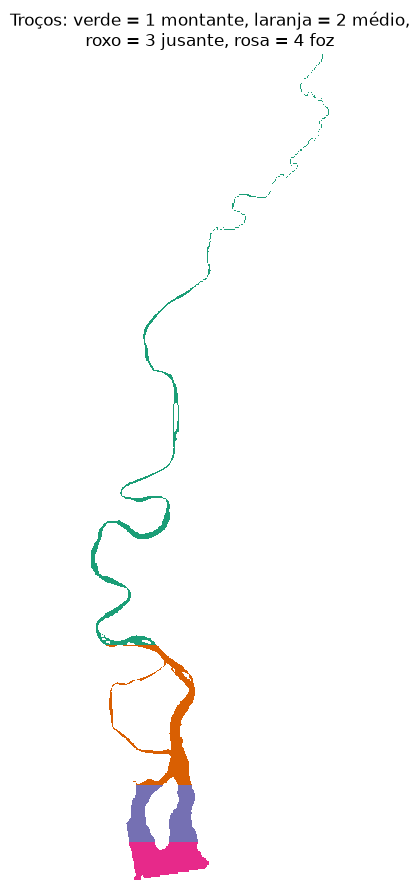

In [2]:
frame = W.river_frame(cfg)
print(f"área medida: {frame['core'].sum() * 100 / 1e6:.1f} km² de rio, em {frame['core'].sum():,} píxeis de 10 m")
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(4.5, 9))
ax.imshow(np.where(frame["reach"] > 0, frame["reach"], np.nan)[::3, ::3], cmap=ListedColormap(["#1b9e77", "#d95f02", "#7570b3", "#e7298a"]), interpolation="nearest")
ax.set_title("Troços: verde = 1 montante, laranja = 2 médio,\nroxo = 3 jusante, rosa = 4 foz"); ax.axis("off")
plt.tight_layout(); plt.savefig(REPORTS / "34_trocos_do_rio.png", dpi=110)

## 2. Série mensal 2017–2026

In [3]:
series_file = drivers.table(cfg, "qualidade_agua_mensal")
quality = W.monthly_series(cfg)                       # lê os 116 meses de Sentinel-2: cerca de 2 minutos
quality.round(5).to_csv(series_file, index=False)
river = quality[quality["troco"] == "rio inteiro"].set_index("month")
print(f"{river['ndti'].notna().sum()} de {len(river)} meses com medição; em média {100 * river['parte_do_troco_observada'].mean():.0f} % do canal observado como água")
river[["ndti", "ndci", "red", "pixeis_de_agua", "n_obs"]].describe().loc[["min", "25%", "50%", "75%", "max"]].round(3)

116 de 116 meses com medição; em média 95 % do canal observado como água


,ndti,ndci,red,pixeis_de_agua,n_obs
min,-0.249,-0.113,0.029,"1,740.000",1.000
25%,-0.088,-0.040,0.044,"297,808.250",5.000
50%,-0.054,-0.001,0.053,"302,410.500",7.000
75%,-0.021,0.015,0.069,"304,667.500",9.000
max,0.045,0.059,0.123,"308,569.000",14.000


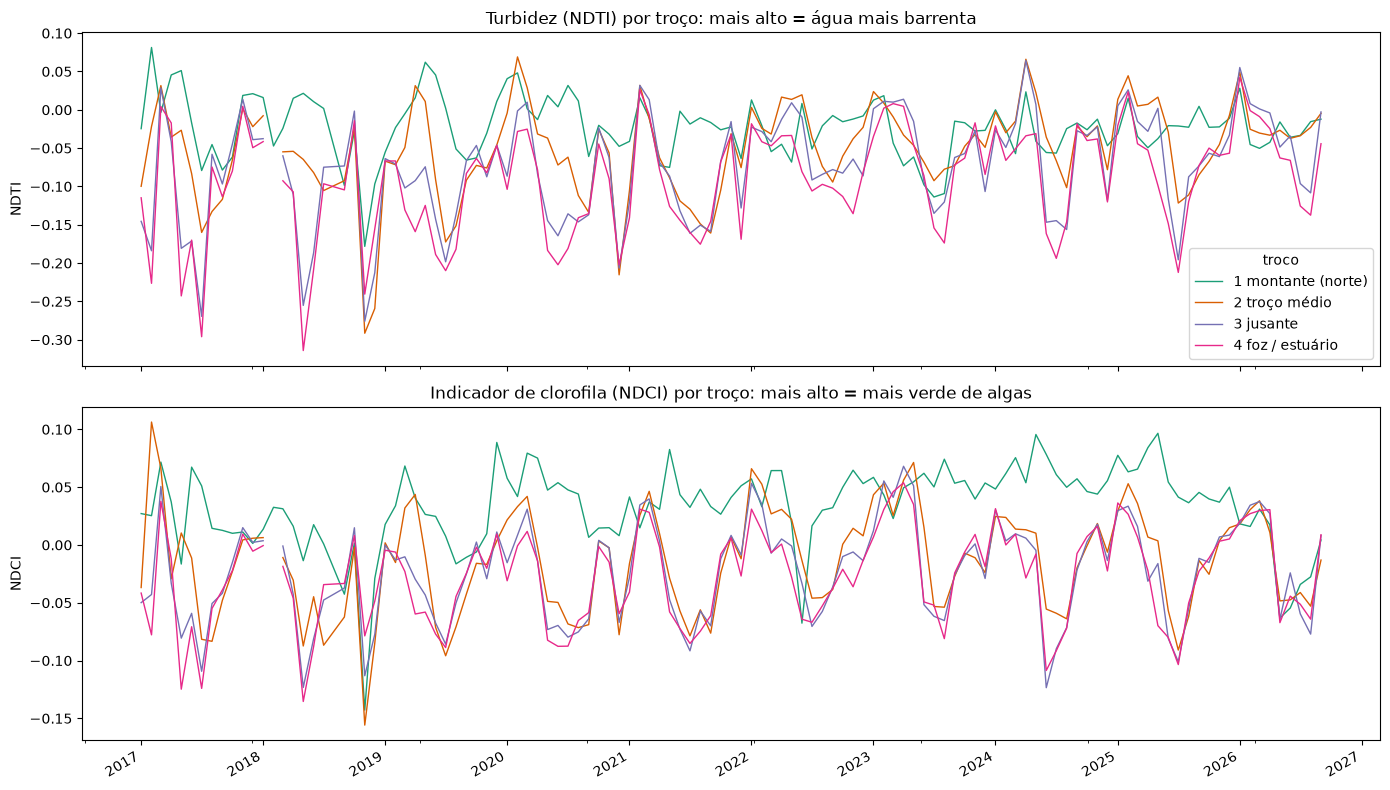

In [4]:
wide = lambda col: quality[quality["troco"] != "rio inteiro"].pivot(index="month", columns="troco", values=col).set_axis(
    pd.to_datetime(sorted(quality["month"].unique())), axis=0)
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
wide("ndti").plot(ax=axes[0], color=["#1b9e77", "#d95f02", "#7570b3", "#e7298a"], linewidth=1)
axes[0].set_ylabel("NDTI"); axes[0].set_title("Turbidez (NDTI) por troço: mais alto = água mais barrenta")
wide("ndci").plot(ax=axes[1], color=["#1b9e77", "#d95f02", "#7570b3", "#e7298a"], linewidth=1, legend=False)
axes[1].set_ylabel("NDCI"); axes[1].set_title("Indicador de clorofila (NDCI) por troço: mais alto = mais verde de algas")
plt.tight_layout(); plt.savefig(REPORTS / "34_series_por_troco.png", dpi=110)

## 3. O padrão ao longo do ano

Mediana de cada mês do calendário, com todos os anos juntos. A faixa mostra a
metade central dos valores.

mes,1,2,3,4,5,6,7,8,9,10,11,12
ndti,-0.013,-0.023,-0.022,-0.028,-0.038,-0.090,-0.107,-0.106,-0.074,-0.046,-0.049,-0.068
ndci,0.013,0.028,0.031,0.008,-0.014,-0.042,-0.054,-0.046,-0.027,0.003,0.011,-0.001


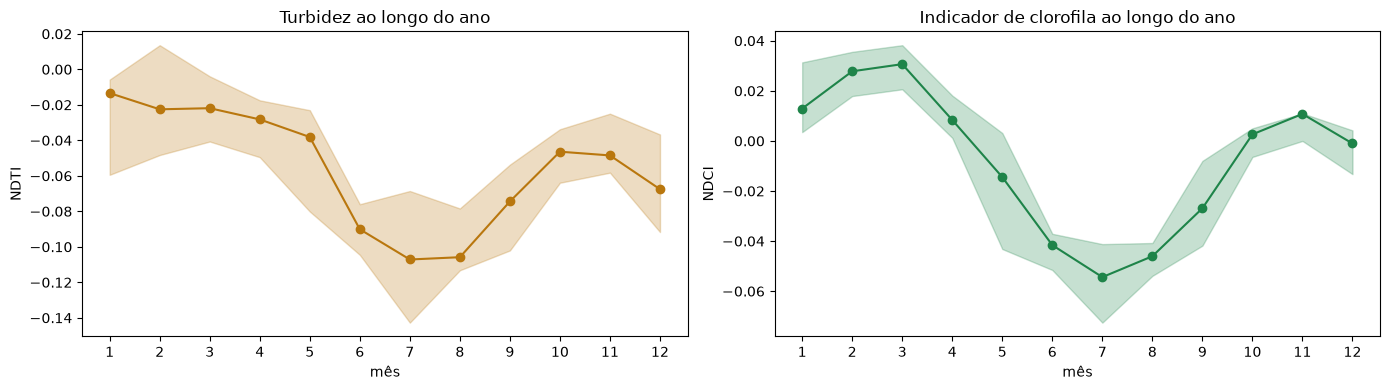

In [5]:
river["mes"] = river.index.str[5:].astype(int)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col, colour in zip(axes, ["ndti", "ndci"], ["#b9770e", "#1e8449"]):
    g = river.groupby("mes")[col]
    ax.fill_between(range(1, 13), g.quantile(0.25), g.quantile(0.75), color=colour, alpha=0.25)
    ax.plot(range(1, 13), g.median(), color=colour, marker="o")
    ax.set_xticks(range(1, 13)); ax.set_xlabel("mês"); ax.set_ylabel(col.upper())
axes[0].set_title("Turbidez ao longo do ano"); axes[1].set_title("Indicador de clorofila ao longo do ano")
plt.tight_layout(); plt.savefig(REPORTS / "34_sazonalidade.png", dpi=110)
river.groupby("mes")[["ndti", "ndci"]].median().round(3).T

## 4. Os indicadores fazem sentido? Comparação com o caudal e a chuva

Não há medições no rio para confirmar os índices. Mas há uma verificação física:
quando o rio leva mais água, arrasta mais sedimentos, e a turbidez tem de subir.
Se o NDTI acompanhar o caudal, é sinal de que está a medir algo real.

,q_mean,q_max,rain_basin_mm,ndti
ndti,0.630,0.610,0.450,1.000
ndci,0.720,0.700,0.600,0.810
red,0.300,0.340,0.590,0.460


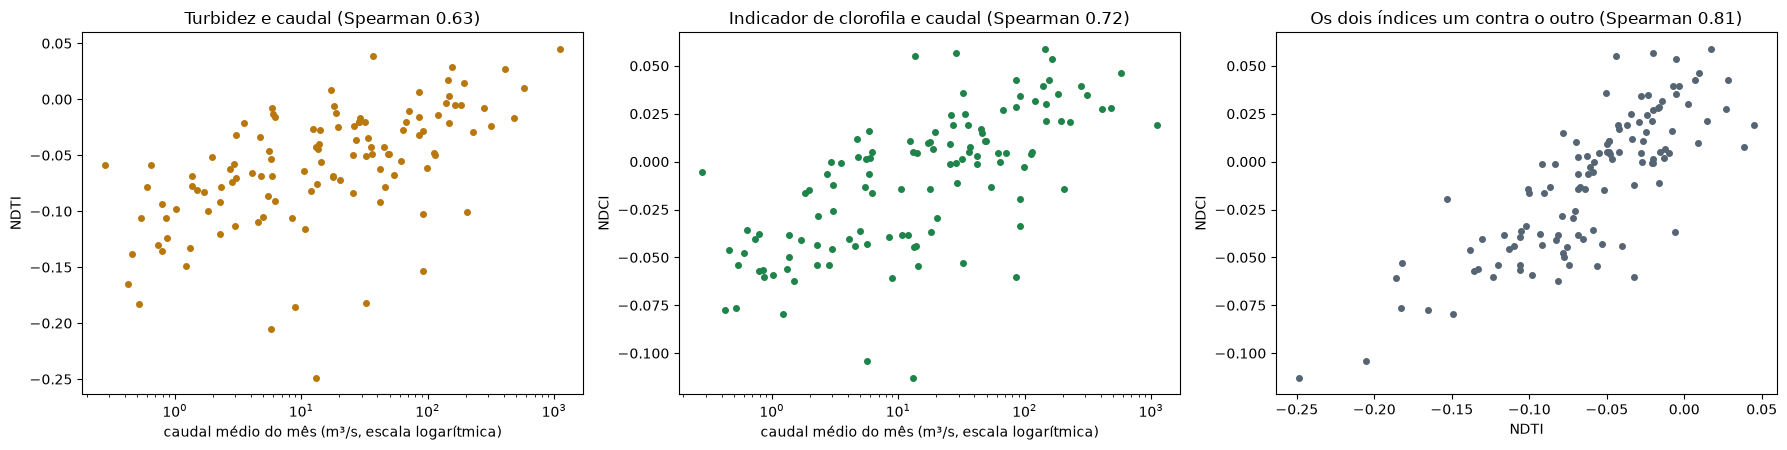

In [6]:
drv = drivers.load_monthly_drivers(cfg)
both = river.join(drv[["q_mean", "q_max", "rain_basin_mm"]]).dropna(subset=["ndti", "q_mean"])
corr = both[["ndti", "ndci", "red", "q_mean", "q_max", "rain_basin_mm"]].corr(method="spearman").loc[["ndti", "ndci", "red"], ["q_mean", "q_max", "rain_basin_mm", "ndti"]]
corr.round(2).to_csv(REPORTS / "34_correlacao_com_caudal.csv")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
axes[0].scatter(both["q_mean"], both["ndti"], s=16, color="#b9770e"); axes[0].set_xscale("log")
axes[0].set_xlabel("caudal médio do mês (m³/s, escala logarítmica)"); axes[0].set_ylabel("NDTI"); axes[0].set_title(f"Turbidez e caudal (Spearman {corr.loc['ndti', 'q_mean']:.2f})")
axes[1].scatter(both["q_mean"], both["ndci"], s=16, color="#1e8449"); axes[1].set_xscale("log")
axes[1].set_xlabel("caudal médio do mês (m³/s, escala logarítmica)"); axes[1].set_ylabel("NDCI"); axes[1].set_title(f"Indicador de clorofila e caudal (Spearman {corr.loc['ndci', 'q_mean']:.2f})")
axes[2].scatter(both["ndti"], both["ndci"], s=16, color="#566573"); axes[2].set_xlabel("NDTI"); axes[2].set_ylabel("NDCI")
axes[2].set_title(f"Os dois índices um contra o outro (Spearman {corr.loc['ndci', 'ndti']:.2f})")
plt.tight_layout(); plt.savefig(REPORTS / "34_indices_vs_caudal.png", dpi=110)
corr.round(2)

**Leitura de especialista**

- **O NDTI acompanha o caudal.** A turbidez sobe nos meses de caudal alto e na
  época chuvosa, como a física manda. Sem medições no rio, esta é a melhor prova
  disponível de que o indicador de turbidez é fiável como medida **relativa**.
- **O NDCI não pode ser lido como "algas" neste rio.** Ele sobe e desce quase em
  conjunto com o NDTI (terceiro gráfico) e com o caudal. Em água barrenta, os
  sedimentos também aumentam a reflexão na banda B5, e o índice de clorofila fica
  contaminado. Um aumento do NDCI aqui quer dizer sobretudo "água mais turva",
  não "mais algas". Só seria um sinal de algas se subisse **sem** o NDTI subir,
  o que se pode vigiar (secção 6).

## 5. Mapas: um mês seco e o mês da cheia

data/processed/maps/qualidade_agua/qualidade_agua_marracuene_2022-08_10m.tif


data/processed/maps/qualidade_agua/qualidade_agua_marracuene_2026-01_10m.tif


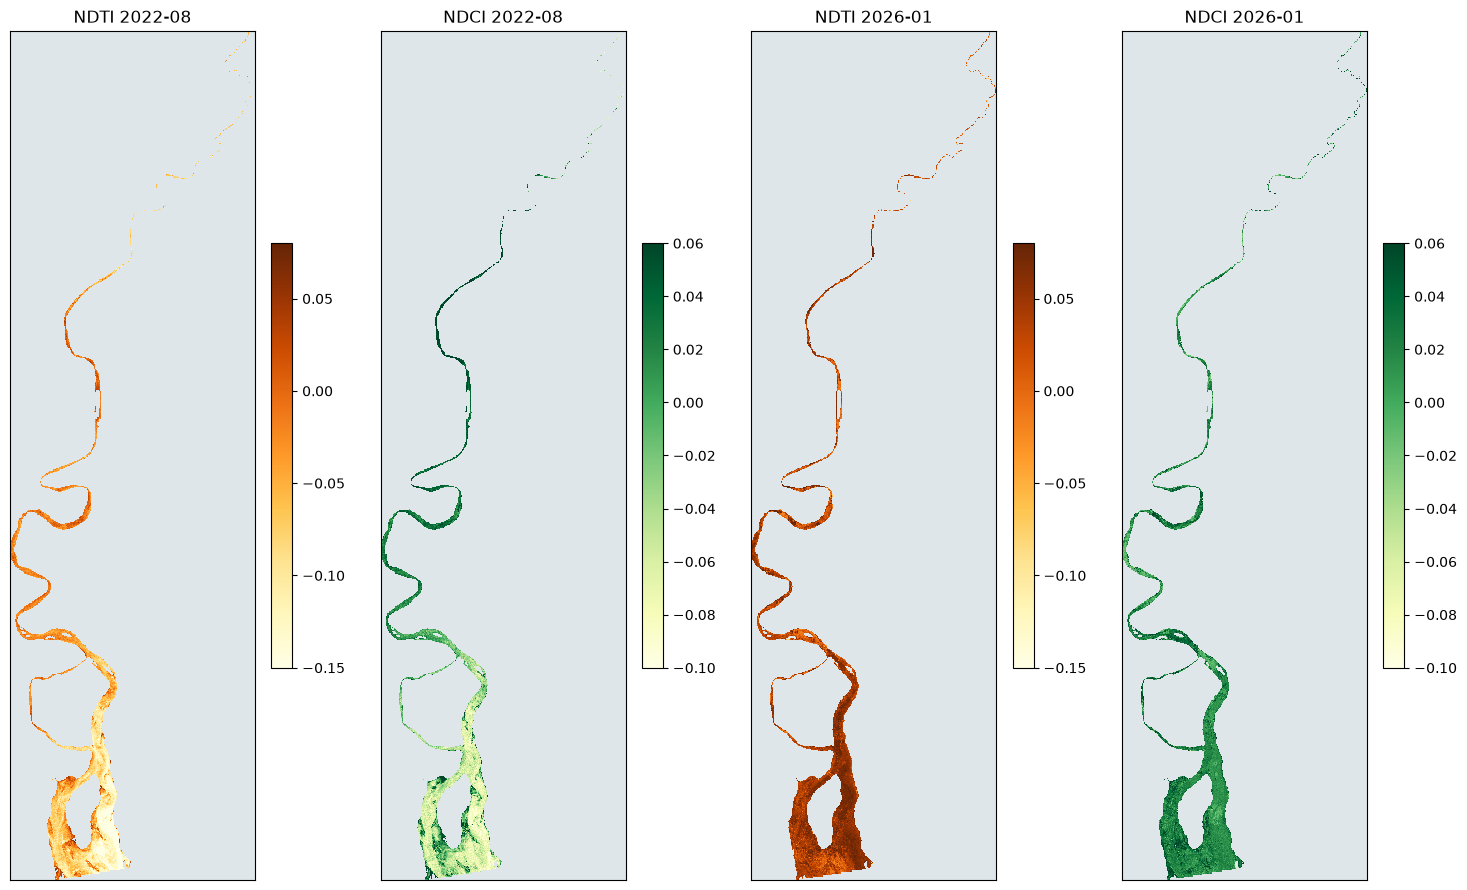

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(15, 9))
for k, month in enumerate(["2022-08", "2026-01"]):
    file, ind, _ = W.quality_map(cfg, month)
    for ax, col, cmap, lim in [(axes[2 * k], "ndti", "YlOrBr", (-0.15, 0.08)), (axes[2 * k + 1], "ndci", "YlGn", (-0.10, 0.06))]:
        im = ax.imshow(ind[col][::3, ::3], cmap=cmap, vmin=lim[0], vmax=lim[1], interpolation="nearest")
        ax.set_facecolor("#dfe6e9"); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{col.upper()} {month}"); plt.colorbar(im, ax=ax, shrink=0.5)
    print(file.relative_to(ROOT))
plt.tight_layout(); plt.savefig(REPORTS / "34_mapas_seco_vs_cheia.png", dpi=110)

Os mapas mostram só o canal do rio. Em janeiro de 2026 (cheia) a água está mais
castanha em todo o rio do que em agosto de 2022 (época seca).

## 6. Indicador para a plataforma: normal, elevado, muito elevado

Como não há valores em unidades reais, cada troço é comparado **com o seu próprio
histórico**: "elevado" = entre os 25 % de meses mais altos desse troço; "muito
elevado" = entre os 10 % mais altos. A última coluna assinala os meses em que o
indicador de clorofila está alto **sem** a turbidez estar: os únicos em que um
sinal de algas é plausível.

In [8]:
quality = quality.sort_values(["troco", "month"])
quality["turbidez"] = quality.groupby("troco")["ndti"].transform(W.relative_class)
quality["clorofila_ind"] = quality.groupby("troco")["ndci"].transform(W.relative_class)
quality["possivel_sinal_de_algas"] = quality["clorofila_ind"].isin(["elevado", "muito elevado"]) & (quality["turbidez"] == "normal")
quality.round(5).to_csv(series_file, index=False)

recent = quality[quality["month"] >= "2025-10"].pivot(index="month", columns="troco", values="turbidez")
print("Turbidez nos últimos 12 meses, por troço:"); display(recent)
algas = quality[quality["possivel_sinal_de_algas"] & (quality["troco"] != "rio inteiro")]
print(f"meses e troços com possível sinal de algas (clorofila alta, turbidez normal): {len(algas)}")
algas.groupby("troco").size().to_frame("meses")

Turbidez nos últimos 12 meses, por troço:


troco,1 montante (norte),2 troço médio,3 jusante,4 foz / estuário,rio inteiro
month,,,,,
2025-10,normal,normal,normal,normal,normal
2025-11,normal,normal,normal,normal,normal
2025-12,normal,elevado,normal,normal,normal
2026-01,muito elevado,muito elevado,muito elevado,muito elevado,muito elevado
2026-02,normal,normal,elevado,muito elevado,elevado
2026-03,normal,normal,elevado,muito elevado,normal
2026-04,normal,normal,elevado,elevado,normal
2026-05,normal,normal,normal,normal,normal
2026-06,normal,normal,normal,normal,normal


meses e troços com possível sinal de algas (clorofila alta, turbidez normal): 48


,meses
troco,
1 montante (norte),24
2 troço médio,11
3 jusante,6
4 foz / estuário,7


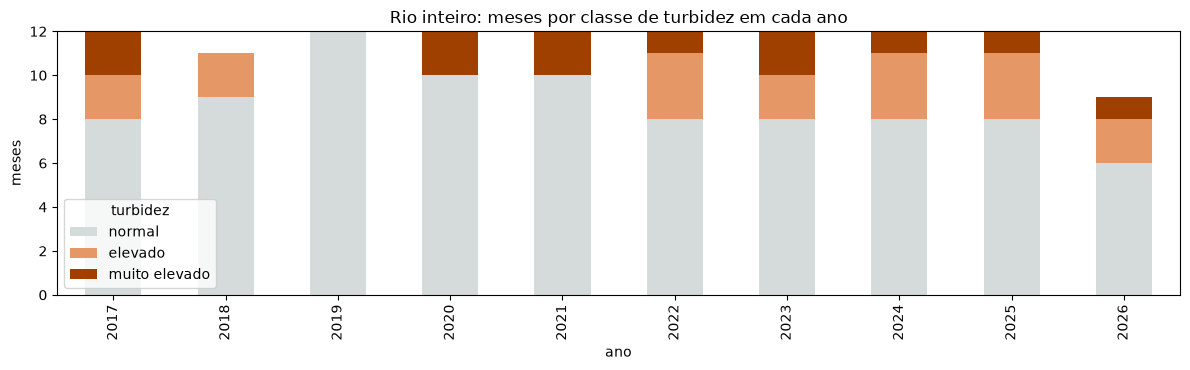

In [9]:
order = ["normal", "elevado", "muito elevado"]
counts = quality[quality["troco"] == "rio inteiro"].assign(ano=lambda d: d["month"].str[:4]).groupby(["ano", "turbidez"]).size().unstack(fill_value=0).reindex(columns=order, fill_value=0)
ax = counts.plot.bar(stacked=True, figsize=(12, 3.8), color=["#d5dbdb", "#e59866", "#a04000"], ylabel="meses", title="Rio inteiro: meses por classe de turbidez em cada ano")
plt.tight_layout(); plt.savefig(REPORTS / "34_turbidez_por_ano.png", dpi=110)

## 7. Vegetação sobre a água

O canal do rio é onde há água quase sempre. Se um píxel do canal aparece verde
na imagem do mês, há plantas sobre a água: plantas flutuantes (como o
jacinto-de-água) ou plantas a crescer em bancos de areia descobertos. O satélite
não distingue a espécie. O indicador é a parte do canal coberta, por troço.

,mediana_%,máximo_%,mês_do_máximo,área_máxima_ha
troco,,,,
1 montante (norte),4.900,33.700,2018-05,263.900
2 troço médio,0.300,3.600,2017-02,27.500
3 jusante,0.100,0.300,2023-05,2.200
4 foz / estuário,0.000,0.400,2026-05,3.400


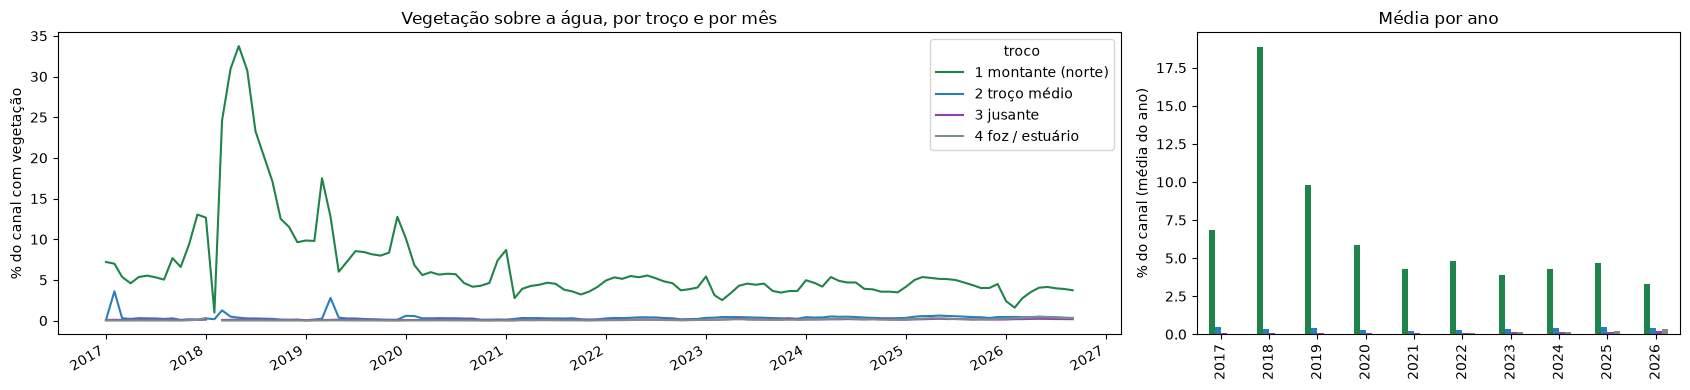

In [10]:
plants = W.channel_vegetation_series(cfg)
cover = 100 * plants.pivot(index="month", columns="troco", values="vegetacao")
cover.index = pd.PeriodIndex(cover.index, freq="M").to_timestamp()
fig, axes = plt.subplots(1, 2, figsize=(17, 4), gridspec_kw={"width_ratios": [2.2, 1]})
cover.plot(ax=axes[0], color=["#1e8449", "#2980b9", "#8e44ad", "#7f8c8d"]); axes[0].set_ylabel("% do canal com vegetação"); axes[0].set_xlabel("")
axes[0].set_title("Vegetação sobre a água, por troço e por mês")
cover.groupby(cover.index.year).mean().plot.bar(ax=axes[1], color=["#1e8449", "#2980b9", "#8e44ad", "#7f8c8d"], legend=False)
axes[1].set_ylabel("% do canal (média do ano)"); axes[1].set_xlabel(""); axes[1].set_title("Média por ano")
plt.tight_layout(); plt.savefig(REPORTS / "34_vegetacao_no_rio.png", dpi=110)
summary = pd.DataFrame({"mediana_%": cover.median(), "máximo_%": cover.max(), "mês_do_máximo": cover.idxmax().dt.strftime("%Y-%m"),
                        "área_máxima_ha": plants.groupby("troco")["area_ha"].max()})
summary.round(1).to_csv(REPORTS / "34_vegetacao_no_rio.csv")
summary.round(1)

**Leitura.** A vegetação sobre a água existe quase só no **troço a montante**.
Nos troços com maré praticamente não há: a água salobra não deixa crescer as
plantas flutuantes de água doce, o que é coerente.

Duas cautelas ao ler o gráfico:

- Os 4 a 5 % que se mantêm todos os anos no troço a montante são, muito
  provavelmente, vegetação fixa (ilhas e bancos dentro do canal). O que
  interessa são as **subidas acima desse nível**.
- O pico de 2018 (um terço do canal) é o sinal mais forte da série, mas em 2017
  e 2018 há menos imagens por mês do que nos anos seguintes. Deve ser confirmado
  com quem conhece o rio antes de ser apresentado como um episódio de plantas
  flutuantes.

Isto explica duas coisas vistas antes: o sinal de clorofila mais alto no troço a
montante, e a medição de turbidez menos fiável aí (notebook 35), porque as
plantas mudam de sítio e tapam partes diferentes do troço de imagem para imagem.

**Para a plataforma:** este indicador pode ser mostrado para o troço a montante
como "parte do rio coberta por plantas". Antes disso, uma visita ao local deve
confirmar de que plantas se trata.

## O que isto vale e o que não vale: leitura de especialista

**O que se pode afirmar com estes dados**

- Quando e em que troço a água esteve **mais turva do que o habitual**, mês a mês
  desde 2017. É um indicador sólido: segue o caudal e a estação, como esperado.
- A turbidez sobe com as cheias. Depois de uma cheia, é quando o tratamento de
  água para consumo fica mais difícil e os pontos de captação devem ser vigiados.

**Um sinal a verificar no terreno.** O troço 1 (montante) tem o indicador de
clorofila mais alto do que os outros desde 2022, muitas vezes sem a turbidez
subir. Pode ser real (algas ou plantas aquáticas flutuantes, como o jacinto-de-água),
mas esse troço é o mais estreito, e as margens e a vegetação podem estar a
entrar nos píxeis. Só uma visita ao local distingue as duas hipóteses.

**O que não se pode afirmar**

- **Valores absolutos.** Sem amostras do rio, não se sabe a quantos NTU (turbidez)
  ou mg/L (sedimentos, clorofila) corresponde um NDTI de 0,03.
- **Se a água é segura para beber, regar ou tomar banho.** A cor não mostra
  bactérias nem poluentes químicos.
- **Algas**, enquanto o NDCI estiver dominado pelos sedimentos.

**Fontes de erro conhecidas**

- A correção atmosférica do Sentinel-2 (L2A) foi feita para terra; sobre água,
  que reflete pouco, o erro relativo é maior.
- No troço da foz, a maré, a ondulação e o fundo visível em água rasa alteram a cor.
- A mediana mensal junta dias diferentes; um episódio de dois dias pode não aparecer.
- Nos meses de cheia há menos imagens sem nuvens (coluna `n_obs`).

**Como transformar o indicador em medição (proposta para a equipa)**

1. Recolher amostras em 3 ou 4 pontos fixos do rio, um por troço, em dias de
   passagem do Sentinel-2 (de 5 em 5 dias) e com céu limpo.
2. Medir no local a turbidez (turbidímetro portátil, em NTU) e a transparência
   (disco de Secchi); se possível, clorofila-a em laboratório.
3. Com 20 a 30 pares "amostra + imagem do mesmo dia" já se pode ajustar uma reta
   entre o NDTI e a turbidez em NTU, e testar se o NDCI responde à clorofila.
4. Até lá, a plataforma deve mostrar as classes relativas (normal / elevado /
   muito elevado) e dizer claramente que são indicadores de cor da água.